<a href="https://colab.research.google.com/github/33ii9r/ARTI502-CNN-CIFAR10/blob/main/ARTI502_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Getting the CIFAR Dataset

Load the CIFAR-10 dataset using `torchvision.datasets.CIFAR10`. CIFAR-10 contains 50,000 training images and 10,000 test images belonging to 10 classes. Each image has three color channels and a resolution of 32 × 32 pixels.

In [1]:
import copy
import os
import random
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
FAST_DEV_RUN = False  # False: train with the full CIFAR-10 dataset.

DATA_PATH = Path(os.environ.get("CIFAR_DATA_PATH", str(Path.cwd() / "data" / "cifar10")))
OUTPUT_DIR = Path.cwd() / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
METRICS_DIR = OUTPUT_DIR / "metrics"
for folder in (DATA_PATH, FIGURE_DIR, CHECKPOINT_DIR, METRICS_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 2))

NUM_WORKERS = 0  # Compatible with Jupyter notebooks on Windows.
PIN_MEMORY = DEVICE.type == "cuda"

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Data directory:", DATA_PATH.resolve())

PyTorch: 2.11.0+cpu
Device: cpu
Data directory: /content/data/cifar10


In [2]:
raw_train = datasets.CIFAR10(root=str(DATA_PATH), train=True, download=True, transform=None)
raw_test = datasets.CIFAR10(root=str(DATA_PATH), train=False, download=True, transform=None)

CLASS_NAMES = list(raw_train.classes)
NUM_CLASSES = len(CLASS_NAMES)
assert len(raw_train) == 50_000 and len(raw_test) == 10_000
assert NUM_CLASSES == 10

first_image, first_label = raw_train[0]
print("CIFAR-10 loaded successfully.")
print(f"Training images: {len(raw_train):,}")
print(f"Test images: {len(raw_test):,}")
print(f"First image size: {first_image.size}")
print(f"First image class: {CLASS_NAMES[first_label]}")
print("Classes:", ", ".join(CLASS_NAMES))

100%|██████████| 170M/170M [27:18<00:00, 104kB/s]


CIFAR-10 loaded successfully.
Training images: 50,000
Test images: 10,000
First image size: (32, 32)
First image class: frog
Classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck


# Task 2: Defining the Network

Two CNN architectures are implemented using `nn.Conv2d`, `nn.ReLU`, and `nn.MaxPool2d`, followed by fully connected classification layers. The enhanced architecture additionally uses batch normalization and dropout. The training and evaluation functions are shared across all experiments.

In [3]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 16x16 -> 8x8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 8x8 -> 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.35),
            nn.Linear(256, num_classes),
        )

    def forward(self, images):
        return self.classifier(self.features(images))


class EnhancedCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.05),
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.10),
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((2, 2)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 2 * 2, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.35),
            nn.Linear(128, num_classes),
        )

    def forward(self, images):
        return self.classifier(self.features(images))


def build_model(architecture):
    if architecture == "simple":
        return SimpleCNN(NUM_CLASSES)
    if architecture == "enhanced":
        return EnhancedCNN(NUM_CLASSES)
    raise ValueError(f"Unknown architecture: {architecture}")


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


for architecture in ("simple", "enhanced"):
    model = build_model(architecture)
    sample_output = model(torch.zeros(2, 3, 32, 32))
    assert sample_output.shape == (2, NUM_CLASSES)
    print(f"\n{architecture.upper()} CNN | Trainable parameters: {count_parameters(model):,}")
    print(model)


SIMPLE CNN | Trainable parameters: 666,538
SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReL

In [4]:
def train_one_epoch(model, loader, optimizer, loss_function, device):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=PIN_MEMORY)
        labels = labels.to(device, non_blocking=PIN_MEMORY)

        optimizer.zero_grad(set_to_none=True)
        predictions = model(images)
        loss = loss_function(predictions, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (predictions.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

    return {
        "loss": total_loss / total_samples,
        "accuracy": 100.0 * total_correct / total_samples,
    }


@torch.inference_mode()
def evaluate(model, loader, loss_function, device):
    model.eval()
    total_loss, total_correct, total_samples = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=PIN_MEMORY)
        labels = labels.to(device, non_blocking=PIN_MEMORY)

        predictions = model(images)
        loss = loss_function(predictions, labels)
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (predictions.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

    return {
        "loss": total_loss / total_samples,
        "accuracy": 100.0 * total_correct / total_samples,
    }

# Task 3: Loading Data

Use a `DataLoader` to inspect the image tensors in `(batch size, channels, height, width)` format and visualize labeled CIFAR-10 samples with Matplotlib.

Images tensor shape (N, C, H, W): (16, 3, 32, 32)
Labels tensor shape (N,): (16,)
Image dtype: torch.float32
Pixel range: 0.000 to 1.000


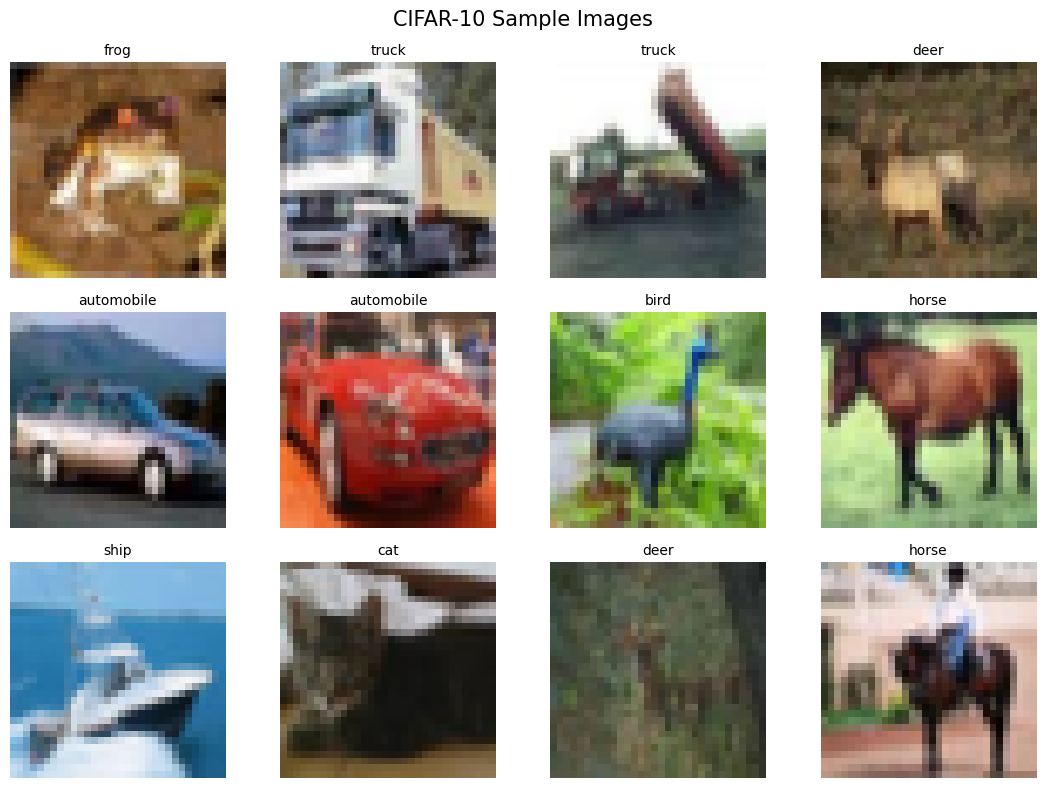

In [5]:
inspection_dataset = datasets.CIFAR10(
    root=str(DATA_PATH), train=True, download=False, transform=transforms.ToTensor()
)
inspection_loader = DataLoader(
    inspection_dataset, batch_size=16, shuffle=False, num_workers=NUM_WORKERS
)
images_batch, labels_batch = next(iter(inspection_loader))

print("Images tensor shape (N, C, H, W):", tuple(images_batch.shape))
print("Labels tensor shape (N,):", tuple(labels_batch.shape))
print("Image dtype:", images_batch.dtype)
print(f"Pixel range: {images_batch.min().item():.3f} to {images_batch.max().item():.3f}")
assert tuple(images_batch.shape) == (16, 3, 32, 32)

fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for index, ax in enumerate(axes.flat):
    ax.imshow(images_batch[index].permute(1, 2, 0).numpy())
    ax.set_title(CLASS_NAMES[int(labels_batch[index])], fontsize=10)
    ax.axis("off")
fig.suptitle("CIFAR-10 Sample Images", fontsize=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "cifar10_samples.png", dpi=160, bbox_inches="tight")
plt.show()

# Task 4: Dataset Augmentation

The transformations explored are `ToPILImage`, `RandomHorizontalFlip`, `RandomResizedCrop`, `ColorJitter`, `RandomRotation`, `Normalize`, Gaussian noise, and `ToTensor`. The training set uses either no random augmentation, mild augmentation, or stronger augmentation. Validation and test images use only `ToTensor` and the same normalization.

In [6]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)


class GaussianNoise:
    def __init__(self, std=0.025):
        self.std = float(std)

    def __call__(self, image_tensor):
        return (image_tensor + torch.randn_like(image_tensor) * self.std).clamp(0, 1)

    def __repr__(self):
        return f"GaussianNoise(std={self.std})"


EVAL_TRANSFORM = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

BASELINE_TRAIN_TRANSFORM = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

MILD_TRAIN_TRANSFORM = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomResizedCrop(32, scale=(0.86, 1.0), ratio=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.12, hue=0.02),
    transforms.RandomRotation(8),
    transforms.ToTensor(),
    GaussianNoise(std=0.015),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

STRONG_TRAIN_TRANSFORM = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomResizedCrop(32, scale=(0.75, 1.0), ratio=(0.85, 1.15)),
    transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.20, hue=0.04),
    transforms.RandomRotation(12),
    transforms.ToTensor(),
    GaussianNoise(std=0.03),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

TRAIN_TRANSFORMS = {
    "none": BASELINE_TRAIN_TRANSFORM,
    "mild": MILD_TRAIN_TRANSFORM,
    "strong": STRONG_TRAIN_TRANSFORM,
}

print("Baseline training transform:\n", BASELINE_TRAIN_TRANSFORM)
print("Mild training transform:\n", MILD_TRAIN_TRANSFORM)
print("Strong training transform:\n", STRONG_TRAIN_TRANSFORM)
print("Validation/test transform:\n", EVAL_TRANSFORM)

Baseline training transform:
 Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)
Mild training transform:
 Compose(
    RandomHorizontalFlip(p=0.5)
    RandomResizedCrop(size=(32, 32), scale=(0.86, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    ColorJitter(brightness=(0.88, 1.12), contrast=(0.88, 1.12), saturation=(0.88, 1.12), hue=(-0.02, 0.02))
    RandomRotation(degrees=[-8.0, 8.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    GaussianNoise(std=0.015)
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)
Strong training transform:
 Compose(
    RandomHorizontalFlip(p=0.5)
    RandomResizedCrop(size=(32, 32), scale=(0.75, 1.0), ratio=(0.85, 1.15), interpolation=bilinear, antialias=True)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.04, 0.04))
    RandomRotation(degrees=[-12.0, 12.0], interpolation=nearest, expand=False, fill=0)
  

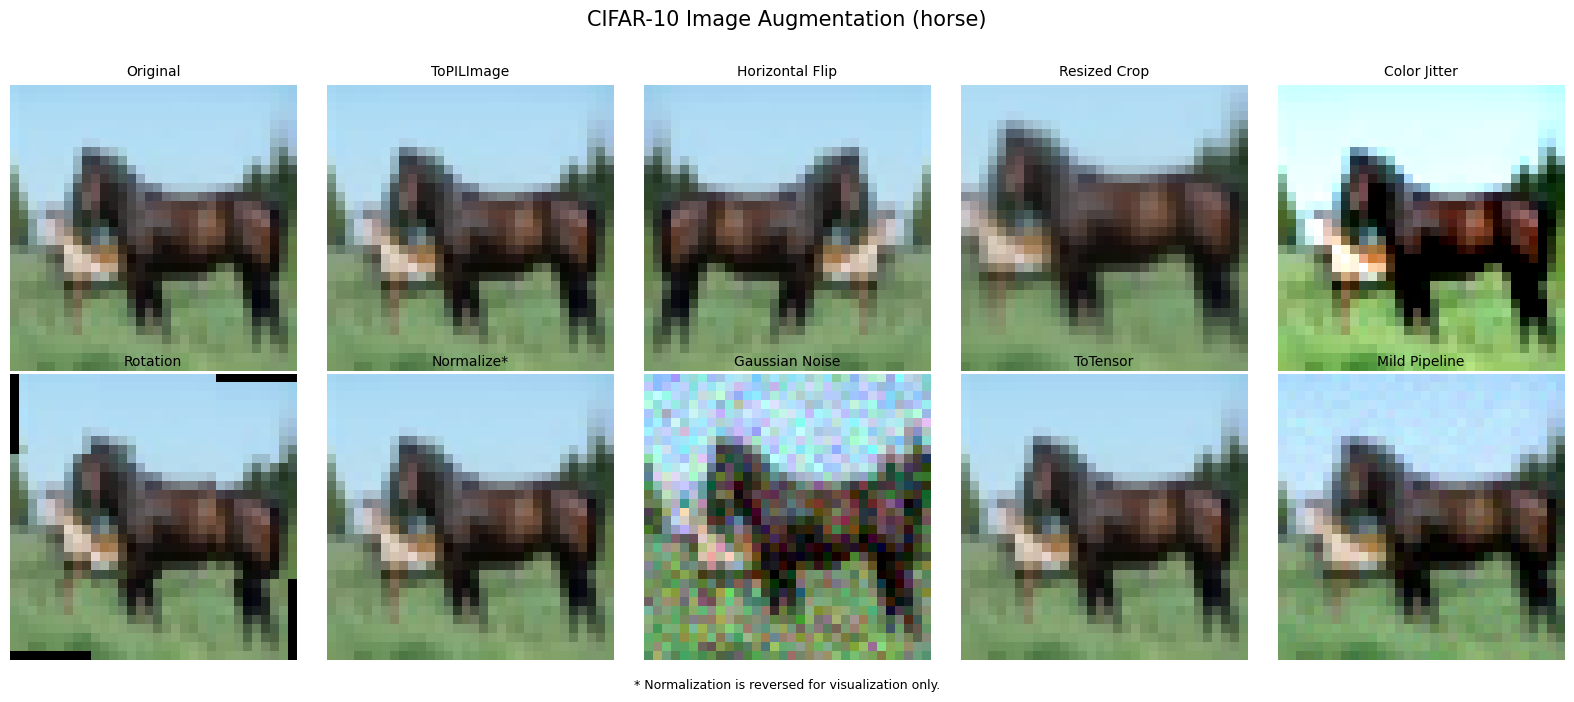

In [7]:
example_pil, example_label = raw_train[12]
example_tensor = transforms.ToTensor()(example_pil)
example_as_pil = transforms.ToPILImage()(example_tensor)

mean_tensor = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(CIFAR_STD).view(3, 1, 1)


def tensor_for_display(image_tensor, normalized=False):
    if normalized:
        image_tensor = image_tensor * std_tensor + mean_tensor
    return image_tensor.clamp(0, 1).permute(1, 2, 0).numpy()


augmentation_examples = [
    ("Original", np.asarray(example_pil)),
    ("ToPILImage", np.asarray(example_as_pil)),
    ("Horizontal Flip", np.asarray(transforms.RandomHorizontalFlip(p=1.0)(example_pil))),
    ("Resized Crop", np.asarray(transforms.RandomResizedCrop(32, scale=(0.70, 0.85))(example_pil))),
    ("Color Jitter", np.asarray(transforms.ColorJitter(0.4, 0.4, 0.4, 0.06)(example_pil))),
    ("Rotation", np.asarray(transforms.RandomRotation(25)(example_pil))),
    ("Normalize*", tensor_for_display(transforms.Normalize(CIFAR_MEAN, CIFAR_STD)(example_tensor), True)),
    ("Gaussian Noise", tensor_for_display(GaussianNoise(0.08)(example_tensor))),
    ("ToTensor", tensor_for_display(example_tensor)),
    ("Mild Pipeline", tensor_for_display(MILD_TRAIN_TRANSFORM(example_pil), True)),
]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, (title, image) in zip(axes.flat, augmentation_examples):
    ax.imshow(image)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
fig.suptitle(f"CIFAR-10 Image Augmentation ({CLASS_NAMES[example_label]})", fontsize=15)
fig.text(0.5, 0.01, "* Normalization is reversed for visualization only.", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig(FIGURE_DIR / "augmentation_examples.png", dpi=160, bbox_inches="tight")
plt.show()

# Task 5: Training Function and Hyperparameter Tuning

The CIFAR-10 training data is split into 90% training and 10% validation data, using a fixed random seed and balanced class proportions. The original CIFAR-10 test set remains separate. Experiments compare CNN architectures, augmentation levels, optimizers, learning rates, batch sizes, and numbers of epochs. The best checkpoint is selected using validation accuracy (with validation loss as a tie-breaker), not test accuracy.

In [8]:
labels_array = np.asarray(raw_train.targets)
rng = np.random.default_rng(SEED)
train_indices, val_indices = [], []

for class_index in range(NUM_CLASSES):
    class_indices = np.flatnonzero(labels_array == class_index)
    rng.shuffle(class_indices)
    n_validation = int(0.10 * len(class_indices))
    val_indices.extend(class_indices[:n_validation].tolist())
    train_indices.extend(class_indices[n_validation:].tolist())

rng.shuffle(train_indices)
rng.shuffle(val_indices)
test_indices = list(range(len(raw_test)))

if FAST_DEV_RUN:
    train_indices = train_indices[:4000]
    val_indices = val_indices[:1000]
    test_indices = test_indices[:1000]

assert set(train_indices).isdisjoint(val_indices)
print(f"Training samples:   {len(train_indices):,}")
print(f"Validation samples: {len(val_indices):,}")
print(f"Testing samples:    {len(test_indices):,}")


def create_loaders(augmentation, batch_size):
    train_dataset = datasets.CIFAR10(
        root=str(DATA_PATH), train=True, download=False,
        transform=TRAIN_TRANSFORMS[augmentation],
    )
    val_dataset = datasets.CIFAR10(
        root=str(DATA_PATH), train=True, download=False, transform=EVAL_TRANSFORM,
    )
    test_dataset = datasets.CIFAR10(
        root=str(DATA_PATH), train=False, download=False, transform=EVAL_TRANSFORM,
    )

    train_loader = DataLoader(
        Subset(train_dataset, train_indices), batch_size=batch_size, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
        generator=torch.Generator().manual_seed(SEED),
    )
    val_loader = DataLoader(
        Subset(val_dataset, val_indices), batch_size=256, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
    )
    test_loader = DataLoader(
        Subset(test_dataset, test_indices), batch_size=256, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
    )
    return train_loader, val_loader, test_loader

Training samples:   45,000
Validation samples: 5,000
Testing samples:    10,000


## Experimental Configurations

The first two experiments keep the same architecture and hyperparameters to compare performance with and without augmentation. The third experiment evaluates a different CNN architecture with a different optimizer and hyperparameter configuration.

In [9]:
@dataclass(frozen=True)
class ExperimentConfig:
    name: str
    architecture: str
    augmentation: str
    optimizer: str
    lr: float
    batch_size: int
    epochs: int
    weight_decay: float = 0.0


EXPERIMENTS = [
    ExperimentConfig("E1_baseline", "simple", "none", "Adam", 0.0010, 128, 5),
    ExperimentConfig("E2_mild_aug", "simple", "mild", "Adam", 0.0010, 128, 5),
    ExperimentConfig("E3_enhanced", "enhanced", "strong", "AdamW", 0.0008, 64, 8, 0.0001),
]

experiment_settings = pd.DataFrame([asdict(experiment) for experiment in EXPERIMENTS])
display(experiment_settings)
experiment_settings.to_csv(METRICS_DIR / "experiment_settings.csv", index=False)

,name,architecture,augmentation,optimizer,lr,batch_size,epochs,weight_decay
0,E1_baseline,simple,none,Adam,0.0010,128,5,0.0000
1,E2_mild_aug,simple,mild,Adam,0.0010,128,5,0.0000
2,E3_enhanced,enhanced,strong,AdamW,0.0008,64,8,0.0001


In [10]:
def make_optimizer(model, config):
    if config.optimizer == "Adam":
        return torch.optim.Adam(
            model.parameters(), lr=config.lr, weight_decay=config.weight_decay
        )
    if config.optimizer == "AdamW":
        return torch.optim.AdamW(
            model.parameters(), lr=config.lr, weight_decay=config.weight_decay
        )
    raise ValueError(f"Unsupported optimizer: {config.optimizer}")


def fit_model(config):
    seed_everything(SEED)
    model = build_model(config.architecture).to(DEVICE)
    loss_function = nn.CrossEntropyLoss()
    optimizer = make_optimizer(model, config)
    train_loader, val_loader, test_loader = create_loaders(config.augmentation, config.batch_size)

    history = []
    best_val_accuracy = float("-inf")
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None

    print(f"\nExperiment: {config.name}")
    for epoch in range(1, config.epochs + 1):
        train_metrics = train_one_epoch(model, train_loader, optimizer, loss_function, DEVICE)
        val_metrics = evaluate(model, val_loader, loss_function, DEVICE)
        test_metrics = evaluate(model, test_loader, loss_function, DEVICE)

        history.append({
            "experiment": config.name,
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "test_loss": test_metrics["loss"],
            "test_accuracy": test_metrics["accuracy"],
        })

        better_checkpoint = (
            val_metrics["accuracy"] > best_val_accuracy
            or (val_metrics["accuracy"] == best_val_accuracy
                and val_metrics["loss"] < best_val_loss)
        )
        if better_checkpoint:
            best_val_accuracy = val_metrics["accuracy"]
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            torch.save({
                "model_state_dict": best_state,
                "configuration": asdict(config),
                "best_epoch": best_epoch,
                "best_validation_accuracy": best_val_accuracy,
                "class_names": CLASS_NAMES,
            }, CHECKPOINT_DIR / f"{config.name}_best.pth")

        print(
            f"Epoch {epoch:02d}/{config.epochs:02d} | "
            f"Train Loss: {train_metrics['loss']:.4f} | "
            f"Validation Loss: {val_metrics['loss']:.4f} | "
            f"Test Loss: {test_metrics['loss']:.4f} | "
            f"Test Accuracy: {test_metrics['accuracy']:.2f}%"
        )

    history_df = pd.DataFrame(history)
    history_df.to_csv(METRICS_DIR / f"{config.name}_history.csv", index=False)

    model.load_state_dict(best_state)
    best_checkpoint_test_metrics = evaluate(model, test_loader, loss_function, DEVICE)
    selected_epoch_metrics = history_df.loc[history_df["epoch"] == best_epoch].iloc[0]
    final_epoch_metrics = history_df.iloc[-1]

    summary = {
        **asdict(config),
        "parameters": count_parameters(model),
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
        "train_loss_at_best_epoch": float(selected_epoch_metrics["train_loss"]),
        "final_train_loss": float(final_epoch_metrics["train_loss"]),
        "final_test_loss": float(final_epoch_metrics["test_loss"]),
        "final_test_accuracy": float(final_epoch_metrics["test_accuracy"]),
        "best_checkpoint_test_loss": best_checkpoint_test_metrics["loss"],
        "best_checkpoint_test_accuracy": best_checkpoint_test_metrics["accuracy"],
    }
    return model, history_df, summary

## Model Training and Evaluation

For each epoch, record training loss, validation loss, test loss, and test accuracy. The saved model weights correspond to the epoch with the best validation performance.

In [11]:
trained_models = {}
training_histories = {}
experiment_results = []

for configuration in EXPERIMENTS:
    model, history, summary = fit_model(configuration)
    trained_models[configuration.name] = model
    training_histories[configuration.name] = history
    experiment_results.append(summary)

comparison_df = pd.DataFrame(experiment_results).sort_values(
    ["best_val_accuracy", "best_val_loss"], ascending=[False, True]
).reset_index(drop=True)

comparison_df.to_csv(METRICS_DIR / "experiment_comparison.csv", index=False)
display(comparison_df[[
    "name", "architecture", "augmentation", "optimizer", "lr",
    "batch_size", "epochs", "best_epoch", "best_val_accuracy", "best_val_loss",
    "final_train_loss", "final_test_loss", "final_test_accuracy",
    "best_checkpoint_test_loss", "best_checkpoint_test_accuracy",
]].round(4))


Experiment: E1_baseline
Epoch 01/05 | Train Loss: 1.5819 | Validation Loss: 1.2216 | Test Loss: 1.2286 | Test Accuracy: 55.15%
Epoch 02/05 | Train Loss: 1.1285 | Validation Loss: 0.9875 | Test Loss: 1.0011 | Test Accuracy: 64.31%
Epoch 03/05 | Train Loss: 0.9190 | Validation Loss: 0.8522 | Test Loss: 0.8707 | Test Accuracy: 69.42%
Epoch 04/05 | Train Loss: 0.7902 | Validation Loss: 0.7411 | Test Loss: 0.7603 | Test Accuracy: 74.17%
Epoch 05/05 | Train Loss: 0.6889 | Validation Loss: 0.7206 | Test Loss: 0.7480 | Test Accuracy: 74.16%

Experiment: E2_mild_aug
Epoch 01/05 | Train Loss: 1.6501 | Validation Loss: 1.2952 | Test Loss: 1.2894 | Test Accuracy: 52.26%
Epoch 02/05 | Train Loss: 1.2974 | Validation Loss: 1.0946 | Test Loss: 1.1010 | Test Accuracy: 60.76%
Epoch 03/05 | Train Loss: 1.1215 | Validation Loss: 0.9081 | Test Loss: 0.9293 | Test Accuracy: 67.23%
Epoch 04/05 | Train Loss: 1.0032 | Validation Loss: 0.8103 | Test Loss: 0.8417 | Test Accuracy: 70.59%
Epoch 05/05 | Train Los

,name,architecture,augmentation,optimizer,lr,batch_size,epochs,best_epoch,best_val_accuracy,best_val_loss,final_train_loss,final_test_loss,final_test_accuracy,best_checkpoint_test_loss,best_checkpoint_test_accuracy
0,E3_enhanced,enhanced,strong,AdamW,0.0008,64,8,8,77.74,0.6245,0.8658,0.6648,77.15,0.6648,77.15
1,E1_baseline,simple,none,Adam,0.0010,128,5,5,75.54,0.7206,0.6889,0.7480,74.16,0.7480,74.16
2,E2_mild_aug,simple,mild,Adam,0.0010,128,5,4,71.26,0.8103,0.9218,0.8711,69.65,0.8417,70.59


## Loss and Accuracy Curves

The plots show training loss, test loss, and test accuracy over the training epochs. A second comparison illustrates how these metrics change across the three experimental configurations.

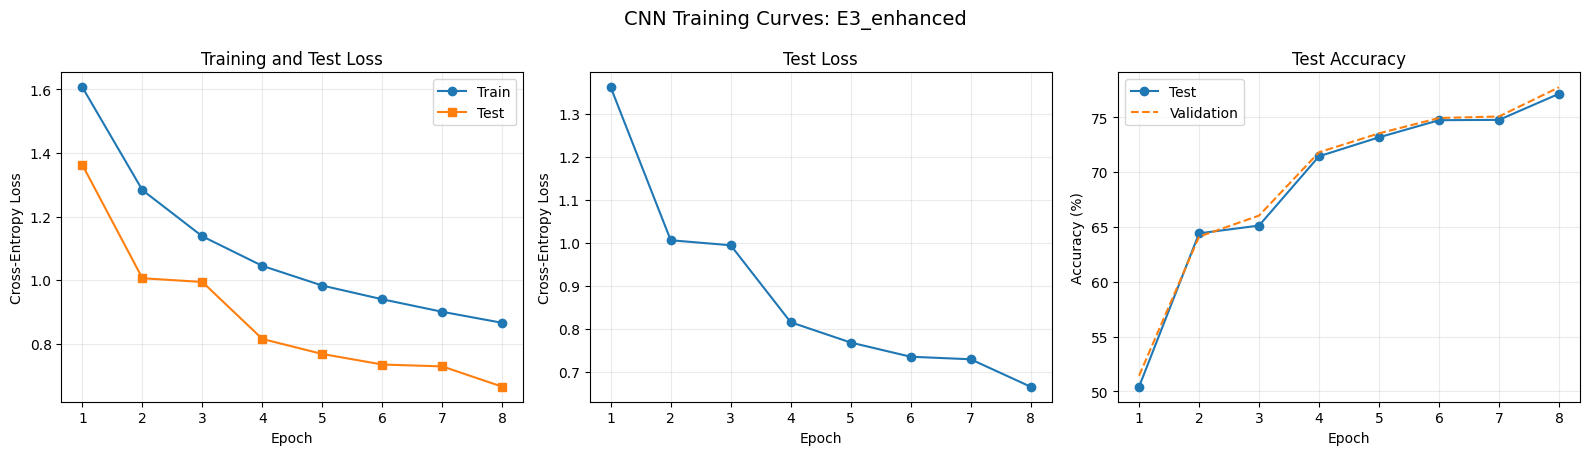

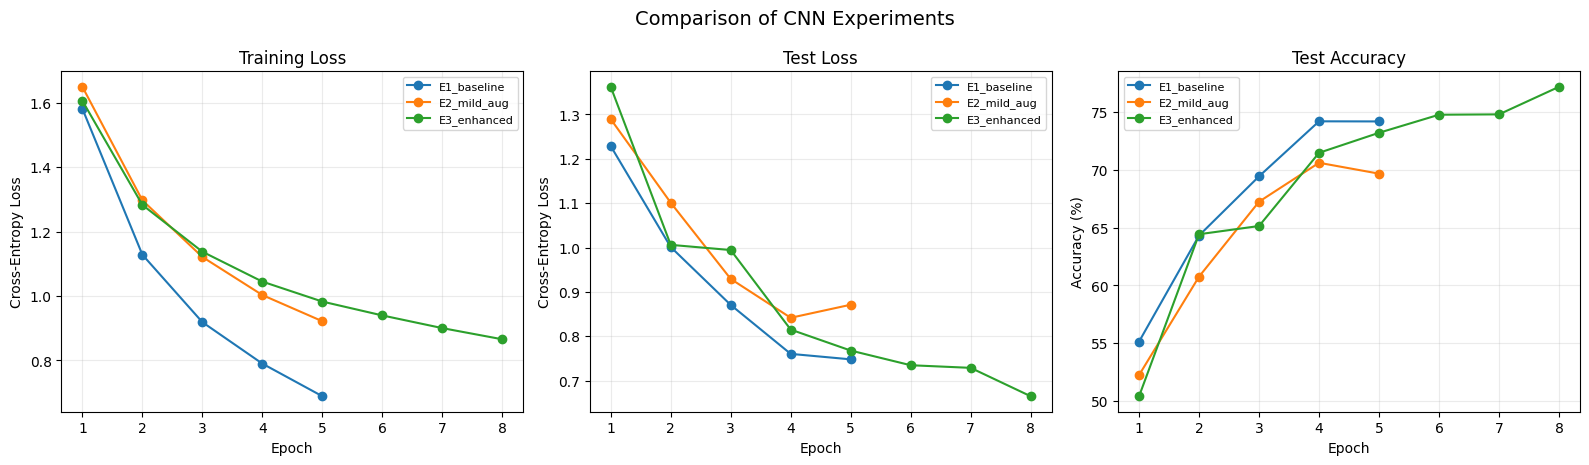

In [12]:
# Select the experiment using validation performance only.
best_experiment = comparison_df.iloc[0]
best_name = best_experiment["name"]
best_history = training_histories[best_name]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].plot(best_history["epoch"], best_history["train_loss"], "o-", label="Train")
axes[0].plot(best_history["epoch"], best_history["test_loss"], "s-", label="Test")
axes[0].set_title("Training and Test Loss")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()

axes[1].plot(best_history["epoch"], best_history["test_loss"], "o-")
axes[1].set_title("Test Loss")
axes[1].set_ylabel("Cross-Entropy Loss")

axes[2].plot(best_history["epoch"], best_history["test_accuracy"], "o-", label="Test")
axes[2].plot(best_history["epoch"], best_history["val_accuracy"], "--", label="Validation")
axes[2].set_title("Test Accuracy")
axes[2].set_ylabel("Accuracy (%)")
axes[2].legend()

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.25)
fig.suptitle(f"CNN Training Curves: {best_name}", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "best_model_curves.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.7))
for experiment_name, history in training_histories.items():
    axes[0].plot(history["epoch"], history["train_loss"], marker="o", label=experiment_name)
    axes[1].plot(history["epoch"], history["test_loss"], marker="o", label=experiment_name)
    axes[2].plot(history["epoch"], history["test_accuracy"], marker="o", label=experiment_name)

for ax, title, ylabel in zip(
    axes,
    ("Training Loss", "Test Loss", "Test Accuracy"),
    ("Cross-Entropy Loss", "Cross-Entropy Loss", "Accuracy (%)"),
):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle("Comparison of CNN Experiments", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "experiment_comparison_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## Best Configuration and Final Metrics

The table identifies the configuration selected through validation performance. “Final” metrics are from the last training epoch; the separate checkpoint metrics correspond to the best validation epoch.

In [13]:
selected_result = comparison_df.loc[comparison_df["name"] == best_name].copy()
selected_columns = [
    "name", "architecture", "augmentation", "optimizer", "lr",
    "batch_size", "epochs", "weight_decay", "parameters", "best_epoch",
    "final_train_loss", "final_test_loss", "final_test_accuracy",
    "train_loss_at_best_epoch", "best_checkpoint_test_loss", "best_checkpoint_test_accuracy",
]
display(selected_result[selected_columns].T.rename(columns={selected_result.index[0]: "Value"}))

augmentation_comparison = comparison_df.set_index("name").loc[
    ["E1_baseline", "E2_mild_aug"],
    ["architecture", "augmentation", "optimizer", "lr", "batch_size", "epochs", "final_test_accuracy"],
]
display(augmentation_comparison.round(4))

,Value
name,E3_enhanced
architecture,enhanced
augmentation,strong
optimizer,AdamW
lr,0.0008
batch_size,64
epochs,8
weight_decay,0.0001
parameters,354410
best_epoch,8


,architecture,augmentation,optimizer,lr,batch_size,epochs,final_test_accuracy
name,,,,,,,
E1_baseline,simple,none,Adam,0.001,128,5,74.16
E2_mild_aug,simple,mild,Adam,0.001,128,5,69.65


## Results and Discussion

### Best CNN Architecture

Three experiments were conducted using two CNN architectures: SimpleCNN and EnhancedCNN.

The **EnhancedCNN (E3)** achieved the best performance, with a test accuracy of **77.15%**. This architecture includes convolutional layers, batch normalization, max-pooling, and dropout.

The EnhancedCNN experiment achieved higher accuracy than both SimpleCNN experiments. However, other settings were also changed, so the improvement cannot be attributed to the architecture alone.

### Hyperparameter Tuning

Different training configurations were tested to compare model performance.

| Parameter | E1 | E2 | E3 |
|---|---|---|---|
| Architecture | SimpleCNN | SimpleCNN | EnhancedCNN |
| Optimizer | Adam | Adam | AdamW |
| Learning Rate | 0.001 | 0.001 | 0.0008 |
| Batch Size | 128 | 128 | 64 |
| Epochs | 5 | 5 | 8 |
| Augmentation | None | Mild | Strong |

The best configuration was **E3**, using AdamW with a learning rate of 0.0008, a batch size of 64, and 8 training epochs. It also used weight decay of 0.0001.

The best model checkpoint was selected at epoch 8 based on validation accuracy.

### Final Training Loss, Test Loss, and Test Accuracy

The best-performing experiment (E3) achieved the following results:

- **Training Loss:** 0.8658
- **Test Loss:** 0.6648
- **Test Accuracy:** 77.15%
- **Validation Accuracy:** 77.74%

The training loss decreased from 1.6065 in the first epoch to 0.8658 in the final epoch.

Test accuracy increased from 50.43% to 77.15%, showing that the model improved during training.

The training and test loss curves, along with the test accuracy plot, illustrate this improvement.

### Effect of Data Augmentation

To evaluate the effect of data augmentation, E1 and E2 used the same SimpleCNN architecture and training hyperparameters.

- **E1 (No Augmentation):** 74.16% final test accuracy.
- **E2 (Mild Augmentation):** 69.65% final test accuracy.

Mild augmentation reduced the final test accuracy by **4.51 percentage points** compared with the baseline.

E3 used stronger augmentation and achieved the highest accuracy of 77.15%. However, E3 also used a different architecture and training configuration, so the improvement cannot be explained by augmentation alone.

These results show that data augmentation does not always improve performance under the same training conditions.

### Performance Comparison and Observations

| Experiment | Final Test Loss | Final Test Accuracy |
|---|---|---|
| E1 – SimpleCNN (No Augmentation) | 0.7480 | 74.16% |
| E2 – SimpleCNN (Mild Augmentation) | 0.8711 | 69.65% |
| E3 – EnhancedCNN (Strong Augmentation) | **0.6648** | **77.15%** |

E3 achieved the highest test accuracy and lowest test loss among the three experiments. Its accuracy was **2.99 percentage points higher** than E1.

E1 performed better than E2, indicating that the mild augmentation settings did not improve SimpleCNN performance during the five training epochs.

Overall, **E3 was the best-performing configuration** in these experiments. The results highlight the importance of comparing different network architectures, training parameters, and augmentation techniques when training CNN models on CIFAR-10.